# 8.1.0 - Model: KNN (K-Nearest Neighbors) (baseline variant)

**Training and evaluation of the K-Nearest Neighbors classifier on the baseline TF-IDF data, with dimensionality reduction.**

## Theoretical Foundation

K-Nearest Neighbors is a lazy model

It does not learn an explicit decision boundary during training (unlike Logistic Regression or tree-based models), but instead simply stores the entire training set.

For a new (test) review, it finds the `k` most similar reviews from the training set (according to some distance/similarity measure) and predicts the majority class among them.

## Why dimensionality reduction is necessary - the "curse of dimensionality"

The vocabulary contains 64,803 terms - too many for direct application of KNN.

In very high-dimensional spaces, the concept of "proximity" loses meaning.

The distances between "nearby" and "faraway" points become increasingly similar statistically as the number of dimensions grows (known as the "curse of dimensionality").

KNN is particularly sensitive to high dimensionality because its predictions are directly based on the distance relationships between samples.

Therefore, a high-dimensional space can make it difficult to distinguish between nearby and distant samples (the other models used can work directly with sparse TF-IDF representations without prior dimensionality reduction).

<br>

Why didn't we solve this already in `3_vectorization.ipynb`, for all models at once:
- A bad decision for the remaining 5 models
- Logistic Regression and SVM (linear models) work well, often better, directly in the sparse high-dimensional space
- If we had compressed everything into a certain number of SVD components in advance:
   - We would lose direct (term-level) interpretability for all models (in `5.x`, specific terms are displayed (`not disappoint`, `not recommend`...))
   - We would negatively affect models that do not need compression in the first place
- Where necessary, we solve the problem locally, in the notebook of the model that actually needs it.

## Why `TruncatedSVD`, not `PCA`

`PCA`:
- Requires centering the data (subtracting the mean) before transformation
- Would convert the sparse TF-IDF matrix into a dense one, losing the memory savings that we carefully preserved from `3_vectorization.ipynb` onward

`TruncatedSVD`:
- Works directly on sparse matrices, without centering
- Mathematically close to PCA for our purposes, but more practical for this type of data.

## Processing Pipeline:

1. Load the previously prepared baseline TF-IDF data using the `load_variant()` function

2. Diagnostics:
   - Fit `TruncatedSVD` with a large number of components
   - Examine the cumulative explained variance and display it graphically

3. Selecting the number of components:
   - Test multiple `N_COMPONENTS` values
   - For each value, perform SVD and GridSearchCV on the TRAIN set
   - Compare the results and select the `N_COMPONENTS` with the best CV F1 score

4. Reduce the TRAIN and TEST sets using TruncatedSVD with the selected number of components (fit only on the TRAIN set)

5. Create a `KNeighborsClassifier` and define the `n_neighbors`, `weights`, and `metric` hyperparameter values that will be tested by `GridSearchCV`

6. Call the shared `train_and_evaluate()` function:
    1. GridSearchCV on the TRAIN set:
        - tests all hyperparameter combinations from the param_grid
        - uses k-fold cross-validation (5 folds by default)
        - selects the hyperparameter combination that gives the best F1 score
    2. Final model:
        - after selecting the best hyperparameters, GridSearchCV trains the best model on the entire TRAIN set
    3. Evaluation:
        - the best model is used on the TEST set for the first time
        - accuracy, precision, recall, and F1 are calculated, and a confusion matrix is created
    4. Saving the results


In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_io import load_variant
from src.modeling import train_and_evaluate

from sklearn.decomposition import TruncatedSVD
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

## Data Loading

We load the baseline variant (TF-IDF matrices + labels), saved in `3_vectorization.ipynb`.


In [2]:
X_train, X_test, y_train, y_test = load_variant("baseline")

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

Train: (39665, 64803)
Test:  (9917, 64803)


## Diagnostics: How Many SVD Components Do We Need?

We fit `TruncatedSVD` with a large number of components (`n_components`) once.

`n_components` determines how many new dimensions SVD should use to compress the original 64,803 features.

We examine the cumulative explained variance at multiple points - instead of fitting separately for each candidate (which would be unnecessarily expensive).

We create an SVD with a sufficiently large number of components and then examine how much information we retain when using specific numbers of components.

We look for the point where the curve begins to noticeably flatten out (diminishing returns).


In [3]:
svd_diagnostic = TruncatedSVD(n_components=5000, random_state=1)
svd_diagnostic.fit(X_train)

cumulative_variance = np.cumsum(svd_diagnostic.explained_variance_ratio_)

print("Cumulative explained variance:")
for n in range(500, 5001, 500):
    print(f"  {n:4d} components: {cumulative_variance[n - 1]:.1%}")

Cumulative explained variance:
   500 components: 17.3%
  1000 components: 26.0%
  1500 components: 32.4%
  2000 components: 37.6%
  2500 components: 42.0%
  3000 components: 45.8%
  3500 components: 49.1%
  4000 components: 52.0%
  4500 components: 54.7%
  5000 components: 56.9%


## Visualization of Cumulative Explained Variance

A graphical representation of how cumulative explained variance changes as the number of SVD components increases.

This makes it easier to identify whether there is a clear point after which increasing the number of components provides progressively smaller contributions.

Since the previous numerical analysis did not reveal a clear point where the curve significantly flattens out, we use this graph as an additional visual analysis before selecting the `N_COMPONENTS` value.


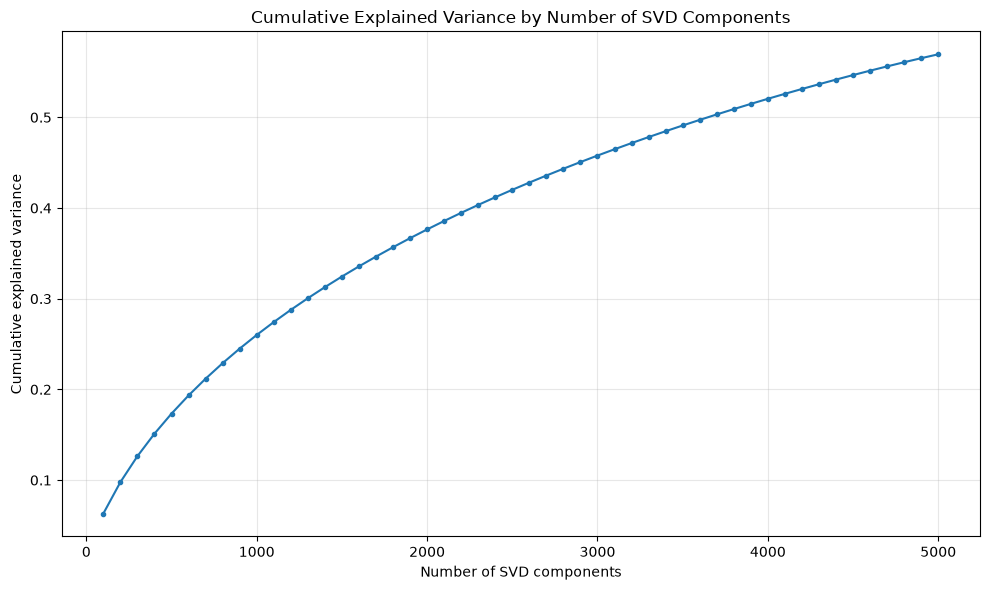

In [4]:
components = list(range(100, 5001, 100))

variance = cumulative_variance[np.array(components) - 1]

plt.figure(figsize=(10, 6))
plt.plot(
    components,
    variance,
    marker="o",
    markersize=3,
    linewidth=1.5
)

plt.xlabel("Number of SVD components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative Explained Variance by Number of SVD Components")

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

## Selecting the Number of Components

Since we did not find a clear point on the diagnostic curve after which explained variance slows down significantly, we cannot reliably select the number of components based on the curve alone. Therefore, we will test several different `N_COMPONENTS` values and select the one that gives the best KNN classifier performance.

`TruncatedSVD` is used to reduce the dimensionality of our TF-IDF data, i.e. to transform a large number of features into a much smaller number of features while attempting to preserve as much useful information as possible.

TruncatedSVD is used because it works directly on sparse matrices (without centering).

It is fitted only on the training set (to prevent data leakage).

The test set is not used during the selection of the number of components.

We take several values for the number of SVD components, compare them, and select the value that gives the best result.

We use hyperparameter values for which we expect good performance, and instead of 5-fold CV we will use 3-fold CV (to save time), while a more detailed search of KNN hyperparameters will be performed after selecting the appropriate number of SVD components:
- `"distance"` - closer neighbors have a greater influence on the vote than more distant ones
- `"cosine"` - measures the angle between two vectors, rather than absolute distance (for text, this is often a better choice because two reviews with similar vocabulary in similar relative proportions should be "close" regardless of their length)


In [ ]:
# Vrednosti broja SVD komponenti koje ćemo uporediti
N_COMPONENTS_CANDIDATES = [500, 1000, 2000, 3000, 4000, 5000]

results = []

for n_components in N_COMPONENTS_CANDIDATES:
    # Transformacija matrice
    svd = TruncatedSVD(n_components=n_components, random_state=1)
    X_train_reduced = svd.fit_transform(X_train)

    # Model i hiperparametri
    param_grid = {
        "n_neighbors": [50, 100, 300],
        "weights": ["distance"],
        "metric": ["cosine"],
    }

    model = KNeighborsClassifier()
    grid_search = GridSearchCV(
        model,
        param_grid,
        cv=3,                       # radi uštede vremena u proveri
        scoring="f1",
        n_jobs=-1
    )

    grid_search.fit(X_train_reduced, y_train)

    # Čuvamo rezultate najboljeg KNN modela za trenutni N_COMPONENTS
    results.append({
        "n_components": n_components,
        "train_shape": X_train_reduced.shape,
        "explained_variance": svd.explained_variance_ratio_.sum(),
        "best_cv_f1": grid_search.best_score_,
        "n_neighbors": grid_search.best_params_["n_neighbors"],
        "weights": grid_search.best_params_["weights"],
        "metric": grid_search.best_params_["metric"]
    })

    print(f"Best F1 for N_COMPONENTS = {n_components}: {grid_search.best_score_:.4f}")

# Ispis rezultata
results_df = pd.DataFrame(results)
results_df

Best F1 for N_COMPONENTS = 500: 0.8064
Best F1 for N_COMPONENTS = 1000: 0.8115
Best F1 for N_COMPONENTS = 2000: 0.8152
Best F1 for N_COMPONENTS = 3000: 0.8190
Best F1 for N_COMPONENTS = 4000: 0.8202
Best F1 for N_COMPONENTS = 5000: 0.8224


,n_components,train_shape,explained_variance,best_cv_f1,n_neighbors,weights,metric
0,500,"(39665, 500)",0.170561,0.806377,100,distance,cosine
1,1000,"(39665, 1000)",0.256770,0.811494,100,distance,cosine
2,2000,"(39665, 2000)",0.372751,0.815195,100,distance,cosine
3,3000,"(39665, 3000)",0.454165,0.818967,100,distance,cosine
4,4000,"(39665, 4000)",0.517453,0.820221,100,distance,cosine
5,5000,"(39665, 5000)",0.569499,0.822413,100,distance,cosine


## Selecting the Best Number of Components and Reducing the Datasets

Based on the CV F1 score, we select the number of SVD components that achieved the best result during validation on the TRAIN set.

With the selected number of components, we fit `TruncatedSVD` again on the TRAIN set and transform the TEST set.

The TEST set is used only now, after the number of components has been selected.


In [6]:
best_n_components = results_df.loc[results_df["best_cv_f1"].idxmax(), "n_components"]

svd = TruncatedSVD(n_components=best_n_components, random_state=1)
X_train_reduced = svd.fit_transform(X_train)
X_test_reduced = svd.transform(X_test)

print(f"Best n_components: {best_n_components}")
print(f"Shape before reduction:  {X_train.shape}")
print(f"Shape after reduction: {X_train_reduced.shape}")
print(f"Explained variance retained: {svd.explained_variance_ratio_.sum():.1%}")

Best n_components: 5000
Shape before reduction:  (39665, 64803)
Shape after reduction: (39665, 5000)
Explained variance retained: 56.9%


## Model and Hyperparameters

Hyperparameters: `n_neighbors`, `weights`, and `metric`

- `n_neighbors` (k) - how many neighbors we consider
  - Small k → more sensitive to individual nearby points (captures noise)
  - Large k → smoother, more stable decision boundary, but may lose local patterns

- `weights` - whether all neighbors "vote" equally
  - `"uniform"` - each of the k neighbors has an equal vote
  - `"distance"` - closer neighbors have a greater influence on the vote than more distant ones

- `metric` - how we measure the "closeness" between two reviews
  - `"euclidean"` - straight-line distance
  - `"cosine"` - measures the angle between two vectors, rather than absolute distance (for text, this is often a better choice because two reviews with similar vocabulary in similar relative proportions should be "close" regardless of their length)


In [7]:
model = KNeighborsClassifier()

param_grid = {
    "n_neighbors": [50, 75, 100, 150, 200],
    "weights": ["uniform", "distance"],
    "metric": ["cosine", "euclidean"],
}

## Training and Evaluation

Calls `train_and_evaluate()` from `src/modeling.py`.

The function tests all specified combinations of `n_neighbors`, `weights`, and `metric` using 5-fold GridSearchCV on the training set, selects the combination with the best F1 score, then trains the best model on the entire training set and evaluates it on the test set.

The results are saved as the model, metrics, and confusion matrix.


========== knn (base) ==========
Best parameters: {'metric': 'cosine', 'n_neighbors': 150, 'weights': 'distance'}
GridSearchCV time: 7186.8s

Accuracy  : 0.8204
Precision : 0.8248
Recall    : 0.8154
F1        : 0.8200


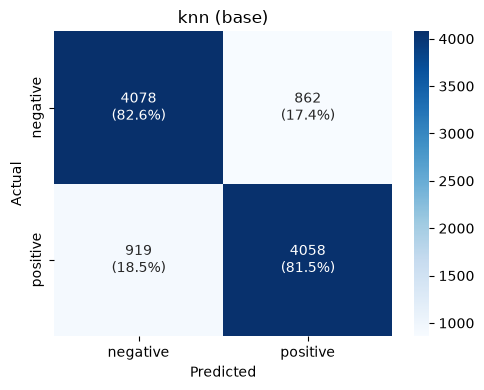


Saved:
  ..\models\knn_base.joblib
  ..\results\metrics\knn_base.json
  ..\results\figures\knn_base_confusion_matrix.png


In [8]:
metrics = train_and_evaluate(
    model=model,
    param_grid=param_grid,
    X_train=X_train_reduced,
    y_train=y_train,
    X_test=X_test_reduced,
    y_test=y_test,
    model_name="knn",
    variant="base",
)

## Conclusions

- The number of SVD components is 5,000, retaining 56.9% of the total explained variance

- The number of components was selected based on the CV F1 score, rather than solely on explained variance. For 5,000 components, the best preliminary CV F1 score was 0.8224

- Cumulative explained variance continued to increase approximately linearly without a clear point of significant slowdown, but due to hardware limitations (insufficient RAM), it was not practically possible to test a larger number of components.

- Best `metric`: cosine, `n_neighbors`: 150, `weights`: distance

- Results:
    - Accuracy  : 0.8204
    - Precision : 0.8248
    - Recall    : 0.8154
    - F1        : 0.8200
